In [67]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

input_path="../data/all_tickets_processed_improved_v3.csv"
output_path=Path("../data/sample.csv")

In [54]:
df1=pd.read_csv(input_path)
print(df1.shape)

(47837, 2)


In [77]:
df.head()

,Document,Topic_group
35333,remove point from laptop remove point laptop h...,Hardware
280,access to re has assigned hi please hi please ...,HR Support
10405,service now update sender contact configuratio...,Miscellaneous
44547,service now ops role groups problem sent monda...,Miscellaneous
17692,new com thursday pm hi please create called ad...,Miscellaneous


In [55]:
target_column="Topic_group"

df,_=train_test_split(
    df1,
    train_size=20000,
    stratify=df1[target_column],
    random_state=42
)

output_path = Path(output_path)
output_path.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(output_path, index=False)



In [56]:
print("Original shape:", df1.shape)
print("Sample shape:", df.shape)
print("Sample category distribution:")
print(df[target_column].value_counts())

Original shape: (47837, 2)
Sample shape: (20000, 2)
Sample category distribution:
Topic_group
Hardware                 5693
HR Support               4563
Access                   2979
Miscellaneous            2952
Storage                  1161
Purchase                 1030
Internal Project          886
Administrative rights     736
Name: count, dtype: int64


inspecting data


In [64]:
df.head(3).reset_index(drop=True)

,Document,Topic_group
0,remove point from laptop remove point laptop h...,Hardware
1,access to re has assigned hi please hi please ...,HR Support
2,service now update sender contact configuratio...,Miscellaneous


In [66]:
text_col = "Document" 
target_col = "Topic_group"

text = df[text_col].fillna("").astype(str)

quality_report = {
    "Total rows": len(df),
    "Missing text": df[text_col].isna().sum(),
    "Missing labels": df[target_col].isna().sum(),
    "Duplicate rows": df.duplicated().sum(),
    "Unique ticket texts": text.nunique(),
    "Unique labels": df[target_col].nunique(),
}

for check, result in quality_report.items():
    print(f"{check}: {result}")

Total rows: 20000
Missing text: 0
Missing labels: 0
Duplicate rows: 0
Unique ticket texts: 20000
Unique labels: 8


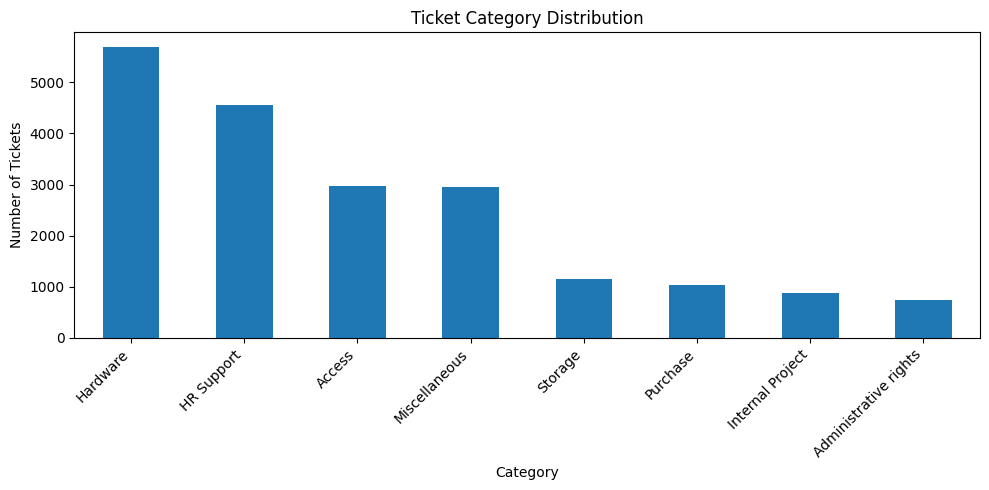

In [70]:
plt.figure(figsize=(10, 5))
df[target_col].value_counts().plot(kind="bar")
plt.title("Ticket Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
df[df[target_col]=="Internal Project"].head(3).reset_index(drop=True)


,Document,Topic_group
0,new client and project codes needed salad orac...,Internal Project
1,rainier communications project setup form pas ...,Internal Project
2,remove from the project assets assets hi pleas...,Internal Project


In [71]:
df[target_col].value_counts()

Topic_group
Hardware                 5693
HR Support               4563
Access                   2979
Miscellaneous            2952
Storage                  1161
Purchase                 1030
Internal Project          886
Administrative rights     736
Name: count, dtype: int64

--Model building

In [72]:
x=df[text_col]
y=df[target_col]

x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)
print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

Training samples: 16000
Testing samples: 4000


In [73]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

In [75]:
def create_pipeline(classifier):
    return Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                max_features=20000,
                ngram_range=(1, 2),
                min_df=2,
                sublinear_tf=True
            )
        ),
        ("classifier", classifier)
    ])

models = {
    "Logistic Regression": create_pipeline(
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Linear SVM": create_pipeline(
        LinearSVC(random_state=42)
    )
}